# 07 — ETAPA 3: Aplicação do método, medidas de acurácia, produto e storytelling

**Projeto Aplicado II — Guilherme Cunha Oliveira (RA 10754621) e Gabriel Lucca Simionato (RA 10751300)**

Este notebook continua o `05_integracao_eda_modelo.ipynb`. Ele faz, em ordem:

1. Aplica a Regressão Logística da Etapa 2, compara com um segundo método (Random Forest) e escolhe o limiar de decisão, tudo na **validação**.
2. Avalia o modelo escolhido **uma única vez** no conjunto de teste reservado, com recall como métrica principal e outras métricas de apoio.
3. Transforma o resultado em um escore de risco (o "produto") e calcula números para o modelo de negócios.
4. Junta os números que sustentam o storytelling.

Pré-requisito: os notebooks 01, 02, 03 e 05 já foram executados.

## ETAPA 1: Bibliotecas, caminhos e variáveis

As listas de variáveis são as mesmas do notebook 05.

In [1]:
import json, gc, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, precision_recall_curve, ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings("ignore")
plt.rcParams.update({"axes.grid": True, "grid.alpha": .3})
pd.set_option("display.width", 160, "display.max_columns", 40)
SEED = 42

RAIZ = Path("..").resolve()
TRATADA = RAIZ/"db/bases_tratadas"
PROC, FIG = TRATADA/"analitica", RAIZ/"reports/figuras"
FIG.mkdir(parents=True, exist_ok=True)

# bases municipais (usadas para montar o conjunto de teste, como no notebook 05)
ibge = pd.read_csv(TRATADA/"ibge/ibge_municipio_2022_tratado.csv", dtype={"cod_municipio": str, "cd_mun_ibge7": str})
cnes = pd.read_csv(TRATADA/"cnes/cnes_municipio_2025_tratado.csv", dtype={"cod_municipio": str})

SINTOMAS = ["FEBRE","MIALGIA","CEFALEIA","EXANTEMA","VOMITO","NAUSEA","DOR_COSTAS","CONJUNTVIT","ARTRITE","ARTRALGIA","PETEQUIA_N","LEUCOPENIA","LACO","DOR_RETRO"]
COMORB   = ["DIABETES","HEMATOLOG","HEPATOPAT","RENAL","HIPERTENSA","ACIDO_PEPT","AUTO_IMUNE"]
NUM_CTX  = ["leitos_10k","leitos_sus_10k","leitos_uti_10k","leitos_uti_sus_10k","n_estabelecimentos","densidade_hab_km2","media_moradores","populacao"]

BINARIAS    = SINTOMAS + COMORB                                    # 0/1
CONTINUAS   = ["idade_anos", "atraso_notif"] + NUM_CTX             # números
CATEGORICAS = ["sexo","gestante","raca","escolaridade","uf_res","mes_sintomas","regiao"]
COLUNAS     = BINARIAS + CONTINUAS + CATEGORICAS
print(len(COLUNAS), "atributos de entrada")

38 atributos de entrada


## ETAPA 2: Dados de desenvolvimento e a mesma divisão da Etapa 2

Usamos a mesma semente (42) e a mesma estratificação do notebook 05, então treino e validação são exatamente os da Etapa 2. O conjunto de teste continua fechado até a Seção 5.

In [2]:
dev = pd.read_parquet(PROC/"base_analitica_dev.parquet")
treino, valid = train_test_split(dev, test_size=0.20, stratify=dev.y, random_state=SEED)
print(f"treino: {len(treino):,} casos | validação: {len(valid):,} casos | % de graves no treino: {treino.y.mean()*100:.2f}%")
print("no relatório da Etapa 2: treino 948.352 e validação 237.089")

treino: 948,352 casos | validação: 237,089 casos | % de graves no treino: 2.55%
no relatório da Etapa 2: treino 948.352 e validação 237.089


## ETAPA 3: Os dois métodos

O pré-processamento é o mesmo da Etapa 2 (moda nos 0/1, mediana e padronização nos números, one-hot nas categorias). A função abaixo só troca o classificador, então a comparação é justa.

- **Regressão Logística** (Etapa 2): soma o efeito de cada atributo. Simples e fácil de interpretar.
- **Random Forest** (segundo método): muitas árvores de decisão, cada uma treinada numa amostra diferente dos dados, que votam juntas. Capta combinações de atributos (por exemplo, idade avançada **e** hipertensão) que a soma da regressão não capta. Os dois usam peso maior para a classe rara (casos graves, 2,55%).

In [3]:
def construir_pipeline(classificador):
    pre = ColumnTransformer([
        ("bin",  SimpleImputer(strategy="most_frequent", add_indicator=True), BINARIAS),
        ("cont", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)), ("escalar", StandardScaler())]), CONTINUAS),
        ("cat",  OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATEGORICAS)])
    return Pipeline([("pre", pre), ("clf", classificador)])

modelos = {
    "Regressão Logística": construir_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": construir_pipeline(RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=50, max_samples=0.3,
                                                              class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
}
probs_valid = {}
for nome, m in modelos.items():
    t0 = time.time()
    m.fit(treino[COLUNAS], treino.y)                                   # o Random Forest pode levar alguns minutos
    probs_valid[nome] = m.predict_proba(valid[COLUNAS])[:, 1]
    print(f"{nome}: treinado em {time.time()-t0:.0f} s")

Regressão Logística: treinado em 39 s
Random Forest: treinado em 46 s


## ETAPA 4: Escolha do modelo e do limiar (só na validação)

**Métricas.** Como só 2,55% dos casos são graves, a acurácia sozinha engana. Usamos:

- **Recall (principal):** dos casos graves, quantos o modelo encontra. É o mais importante, porque deixar passar um caso grave é pior que um alerta falso.
- **Precisão:** dos casos alertados, quantos eram realmente graves.
- **F1, AUC-ROC e AUC-PR:** resumos de apoio. A AUC-PR é a mais adequada para classe rara.

**Escolha do modelo:** o de maior AUC-PR na validação.

**Escolha do limiar:** o limiar 0,5 da Etapa 2 foi só o padrão. Aqui o grupo define uma meta de recall (`RECALL_ALVO`) e usa o **maior limiar que ainda cumpre a meta**, porque quanto maior o limiar, menos alertas e mais precisão.

In [4]:
RECALL_ALVO = 0.70      # decisão do grupo: "queremos encontrar pelo menos 70% dos casos graves"

def escolher_limiar(y, p, recall_alvo):
    prec, rec, lim = precision_recall_curve(y, p)
    ok = np.where(rec[:-1] >= recall_alvo)[0]          # limiares que cumprem a meta
    return float(lim[ok[-1]])                           # o maior deles

def metricas(y, p, limiar):
    y = np.asarray(y); yh = (np.asarray(p) >= limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {"recall": recall_score(y, yh), "precisao": precision_score(y, yh, zero_division=0), "f1": f1_score(y, yh),
            "auc_roc": roc_auc_score(y, p), "auc_pr": average_precision_score(y, p), "acuracia": accuracy_score(y, yh),
            "alertas_pct": yh.mean(), "vp": int(vp), "fp": int(fp), "fn": int(fn), "vn": int(vn)}

linhas = {}
for nome, p in probs_valid.items():
    lim = escolher_limiar(valid.y, p, RECALL_ALVO)
    linhas[nome] = {"limiar": lim, **metricas(valid.y, p, lim)}
tab_valid = pd.DataFrame(linhas).T[["limiar","recall","precisao","f1","auc_roc","auc_pr","alertas_pct"]].round(4)
print(f"VALIDAÇÃO — limiar escolhido para recall ≥ {RECALL_ALVO:.0%}:"); print(tab_valid.to_string())

escolhido = tab_valid.auc_pr.idxmax()
LIMIAR = float(tab_valid.loc[escolhido, "limiar"])
modelo_final, p_valid = modelos[escolhido], probs_valid[escolhido]
print(f"\nModelo escolhido (maior AUC-PR): {escolhido} | limiar: {LIMIAR:.4f}")

VALIDAÇÃO — limiar escolhido para recall ≥ 70%:
                     limiar  recall  precisao      f1  auc_roc  auc_pr  alertas_pct
Regressão Logística  0.4645     0.7     0.050  0.0934   0.7364  0.0796       0.3569
Random Forest        0.4632     0.7     0.077  0.1387   0.8172  0.1520       0.2319

Modelo escolhido (maior AUC-PR): Random Forest | limiar: 0.4632


 recall_alvo  limiar  precisao  casos_alertados_%
         0.5   0.568     0.126             10.089
         0.6   0.517     0.100             15.284
         0.7   0.463     0.077             23.191
         0.8   0.408     0.059             34.809
         0.9   0.347     0.044             52.193


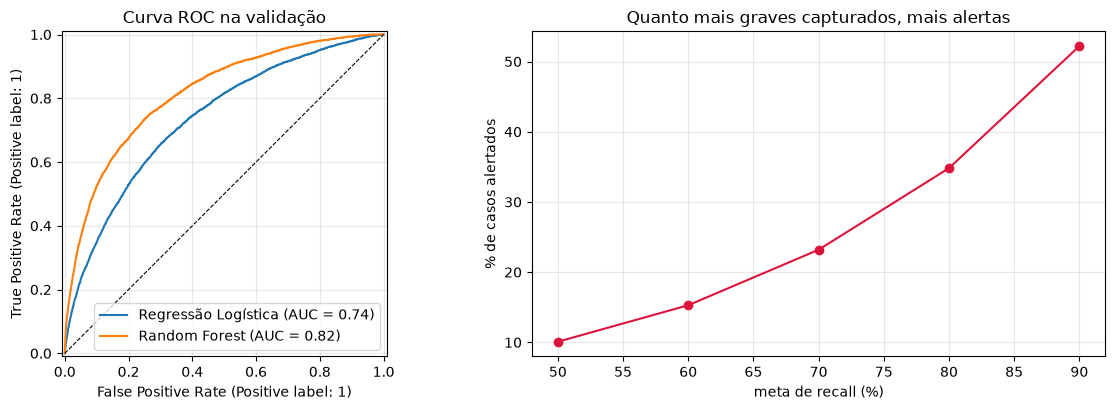

In [5]:
# O que cada meta de recall custa? (modelo escolhido, validação)
prev = valid.y.mean(); comp = []
for alvo in [0.5, 0.6, 0.7, 0.8, 0.9]:
    lim = escolher_limiar(valid.y, p_valid, alvo); m = metricas(valid.y, p_valid, lim)
    comp.append({"recall_alvo": alvo, "limiar": lim, "precisao": m["precisao"], "casos_alertados_%": m["alertas_pct"]*100})
comp = pd.DataFrame(comp).round(3); print(comp.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for nome, p in probs_valid.items(): RocCurveDisplay.from_predictions(valid.y, p, name=nome, ax=ax[0])
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_title("Curva ROC na validação")
ax[1].plot(comp.recall_alvo*100, comp["casos_alertados_%"], "o-", color="crimson")
ax[1].set_xlabel("meta de recall (%)"); ax[1].set_ylabel("% de casos alertados"); ax[1].set_title("Quanto mais graves capturados, mais alertas")
plt.tight_layout(); plt.savefig(FIG/"20_validacao_modelos_e_limiar.png", dpi=120); plt.show()

## ETAPA 5: Avaliação única no conjunto de teste

O teste foi sorteado e reservado no notebook 05 (`split_ids.csv`). Aqui ele é montado com as **mesmas regras** do desenvolvimento (nomes das colunas, região, integração com CNES e IBGE) e passa pelo modelo escolhido, **sem reajustar nada**. O limiar também já está decidido.

⚠️ **Rode esta seção uma vez só.** Se mudar o modelo ou o limiar depois de ver o teste, ele deixa de ser uma avaliação independente.

In [6]:
def integrar(df):
    """Mesma função do notebook 05: junta IBGE e CNES ao caso pelo código do município."""
    n0 = len(df)
    df = df.merge(ibge.drop(columns=["cd_mun_ibge7","uf","regiao"]), on="cod_municipio", how="left", validate="m:1")
    df["competencia_cnes"] = df.competencia.clip(lower=202501, upper=202512)
    df = df.merge(cnes.rename(columns={"competencia": "competencia_cnes"}), on=["cod_municipio","competencia_cnes"], how="left", validate="m:1")
    for c in ["n_estabelecimentos","leitos","leitos_sus","leitos_uti","leitos_uti_sus"]: df[c] = df[c].fillna(0).astype("float32")
    for c in ["leitos","leitos_sus","leitos_uti","leitos_uti_sus"]: df[c + "_10k"] = (df[c] / df.populacao * 1e4).astype("float32")
    assert len(df) == n0
    return df

ids_test = pd.read_csv(PROC/"split_ids.csv").query("conjunto == 'teste'").id_registro.values
sinan = pd.read_parquet(TRATADA/"sinan/sinan_dengue_2025_tratado.parquet")
for c in ["sexo","gestante","raca","escolaridade","uf_res","cod_municipio"]: sinan[c] = sinan[c].astype("category")
teste = sinan[sinan.id_registro.isin(ids_test)].copy(); del sinan; gc.collect()

teste = teste.rename(columns={"dias_ate_notificacao": "atraso_notif"}); teste["y"] = teste.alvo
for c in SINTOMAS + COMORB: teste[c] = teste[c + "_bin"]
teste = teste.merge(ibge[["cod_municipio","regiao"]], on="cod_municipio", how="left")
teste["regiao"] = teste.regiao.fillna("ignorado").astype("category")
teste = integrar(teste)

assert len(teste) == len(ids_test) and not (set(ids_test) & set(dev.id_registro)), "o teste tem de ser separado do desenvolvimento"
print(f"teste: {len(teste):,} casos | graves: {int(teste.y.sum()):,} ({teste.y.mean()*100:.2f}%)")

teste: 296,361 casos | graves: 7,558 (2.55%)


Modelo: Random Forest | limiar: 0.4632

             validação   teste
recall          0.7002  0.7182
precisao        0.0770  0.0787
f1              0.1387  0.1419
auc_pr          0.1520  0.1516
auc_roc         0.8172  0.8238
acuracia        0.7783  0.7784
alertas_pct     0.2320  0.2327

Matriz de confusão no teste: VP=5,428  FP=63,544  FN=2,130  VN=225,259


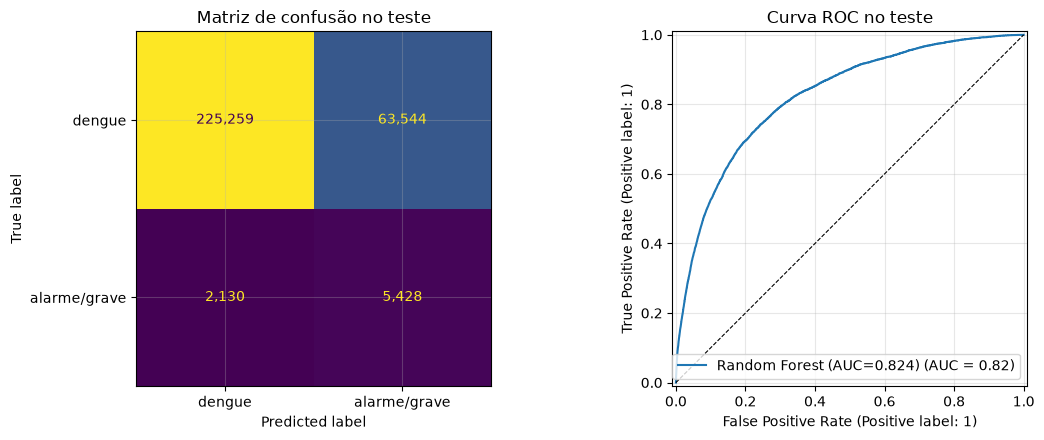

In [7]:
p_teste = modelo_final.predict_proba(teste[COLUNAS])[:, 1]        # única passagem do teste pelo modelo
y_teste = teste.y.values.astype(int)
r = metricas(y_teste, p_teste, LIMIAR)

comparacao = pd.DataFrame({"validação": metricas(valid.y, p_valid, LIMIAR), "teste": r}).loc[["recall","precisao","f1","auc_pr","auc_roc","acuracia","alertas_pct"]].round(4)
print(f"Modelo: {escolhido} | limiar: {LIMIAR:.4f}\n"); print(comparacao.to_string())
print(f"\nMatriz de confusão no teste: VP={r['vp']:,}  FP={r['fp']:,}  FN={r['fn']:,}  VN={r['vn']:,}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_teste, (p_teste >= LIMIAR).astype(int), display_labels=["dengue","alarme/grave"], colorbar=False, ax=ax[0], values_format=",d")
ax[0].set_title("Matriz de confusão no teste")
RocCurveDisplay.from_predictions(y_teste, p_teste, name=f"{escolhido} (AUC={r['auc_roc']:.3f})", ax=ax[1]); ax[1].plot([0, 1], [0, 1], "k--", lw=.8); ax[1].set_title("Curva ROC no teste")
plt.tight_layout(); plt.savefig(FIG/"21_teste_confusao_roc.png", dpi=120); plt.show()

## ETAPA 6: Resultado preliminar e produto

O resultado do modelo para um caso real é um **escore de risco** (de 0 a 1). O produto proposto é um painel de apoio à triagem que, para cada notificação, mostra a faixa:

- **Alto risco:** escore ≥ limiar → acompanhamento prioritário;
- **Baixo risco:** escore < limiar → fluxo habitual, com orientação sobre sinais de alarme.

Abaixo estão os números que o modelo de negócios usa: quantos casos o painel manda olhar e quantos graves ele encontra. O escore ordena os casos, mas **não é a probabilidade clínica real**, porque o modelo dá mais peso à classe rara.

In [8]:
teste["escore"] = p_teste
teste["faixa"] = np.where(p_teste >= LIMIAR, "alto risco", "baixo risco")
graves_total = int(teste.y.sum())
faixas = teste.groupby("faixa").agg(casos=("y", "size"), graves=("y", "sum"))
faixas["% dos casos"] = faixas.casos / len(teste) * 100
faixas["% de graves na faixa"] = faixas.graves / faixas.casos * 100
faixas["% dos graves capturados"] = faixas.graves / graves_total * 100
print("Faixas de risco no TESTE:"); print(faixas.round(2).to_string())

por_mil = {"graves_esperados": 1000*y_teste.mean(), "alertas": 1000*r["alertas_pct"], "graves_capturados": 1000*r["vp"]/len(y_teste)}
print("\nPor 1.000 notificações:", {k: round(float(v), 1) for k, v in por_mil.items()})

# exemplo da saída do produto: 4 casos de cada faixa
exemplo = pd.concat([d.sample(4, random_state=SEED) for _, d in teste.groupby("faixa")])
exemplo = exemplo[["id_registro","idade_anos","VOMITO","LEUCOPENIA","HIPERTENSA","DIABETES","escore","faixa","y"]].copy()
exemplo["escore"] = exemplo.escore.round(2); exemplo["idade_anos"] = exemplo.idade_anos.round(0)
exemplo = exemplo.rename(columns={"y": "evolucao_real (1=alarme/grave)"})
print("\nExemplo da saída do produto (casos do teste):"); print(exemplo.to_string(index=False))
exemplo.to_csv(PROC/"etapa3_exemplo_predicoes.csv", index=False)

Faixas de risco no TESTE:
              casos  graves  % dos casos  % de graves na faixa  % dos graves capturados
faixa                                                                                  
alto risco    68972    5428        23.27                  7.87                    71.82
baixo risco  227389    2130        76.73                  0.94                    28.18

Por 1.000 notificações: {'graves_esperados': 25.5, 'alertas': 232.7, 'graves_capturados': 18.3}

Exemplo da saída do produto (casos do teste):
 id_registro  idade_anos  VOMITO  LEUCOPENIA  HIPERTENSA  DIABETES  escore       faixa  evolucao_real (1=alarme/grave)
      440970        32.0     1.0         0.0         0.0       0.0    0.48  alto risco                               0
     1320176        73.0     1.0         0.0         0.0       0.0    0.46  alto risco                               0
      169849        19.0     1.0         0.0         0.0       0.0    0.47  alto risco                               0
  

## ETAPA 7: Números para o storytelling e resumo

Os informes do COE (notebooks 04 e 06) dão o contexto nacional. Cada linha é um acumulado de SE 1 até a SE final do informe e **não pode ser somada** com outra. O total dos informes e o do SINAN também não validam um ao outro: são definições diferentes.

In [9]:
arq = TRATADA/"informes/informes_indicadores_citados.csv"
if arq.exists():
    ult = pd.read_csv(arq).sort_values("informe_num").iloc[-1]
    print(f"Informe nº {int(ult.informe_num)} (SE 1 a {int(ult.se_fim)}): {ult.casos_provaveis:,.0f} casos prováveis | incidência {ult.incidencia_100mil} por 100 mil | "
          f"variação vs 2024: {ult.variacao_vs_2024_pct}% | óbitos confirmados: {ult.obitos_confirmados:,.0f} | em investigação: {ult.obitos_investigacao:,.0f} | sorotipo predominante: {ult.sorotipo_predominante}")
else:
    print("Rode o notebook 06 para preencher o contexto dos informes.")

Informe nº 17 (SE 1 a 23): 1,478,752 casos prováveis | incidência 728.2 por 100 mil | variação vs 2024: -75.7% | óbitos confirmados: 1,165 | em investigação: 752 | sorotipo predominante: DENV-2


In [10]:
def pct(x, c=1): return f"{x*100:.{c}f}%".replace(".", ",")
def num(x, c=3): return f"{x:.{c}f}".replace(".", ",")
def mil(x): return f"{int(round(x)):,}".replace(",", ".")

print("=== CAMPOS PARA O RELATÓRIO (copie o valor ao lado do nome) ===")
campos = {
  "modelo_escolhido": escolhido,
  "recall_alvo": pct(RECALL_ALVO, 0),
  "limiar": num(LIMIAR, 3),
  "n_treino / n_validacao": f"{mil(len(treino))} / {mil(len(valid))}",
  "n_teste / graves_teste": f"{mil(len(y_teste))} / {mil(y_teste.sum())} ({pct(y_teste.mean(), 2)})",
  "recall_teste": pct(r["recall"]), "precisao_teste": pct(r["precisao"]), "f1_teste": num(r["f1"]),
  "auc_pr_teste": num(r["auc_pr"]), "auc_roc_teste": num(r["auc_roc"]), "acuracia_teste": pct(r["acuracia"]),
  "alertas_teste": pct(r["alertas_pct"]),
  "VP / FP / FN / VN": " / ".join(mil(r[k]) for k in ["vp","fp","fn","vn"]),
  "por_mil (graves esperados / alertas / graves capturados)": f"{num(por_mil['graves_esperados'],1)} / {num(por_mil['alertas'],0)} / {num(por_mil['graves_capturados'],1)}",
}
for k, v in campos.items(): print(f"{k:58s} {v}")

print("\n=== TABELA DE VALIDAÇÃO (modelos comparados) ==="); print(tab_valid.to_string())
print("\n=== FAIXAS DE RISCO (teste) ==="); print(faixas.round(1).to_string())
(PROC/"resumo_etapa3.json").write_text(json.dumps({"campos": campos, "validacao": tab_valid.reset_index().to_dict(orient="records")}, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

=== CAMPOS PARA O RELATÓRIO (copie o valor ao lado do nome) ===
modelo_escolhido                                           Random Forest
recall_alvo                                                70%
limiar                                                     0,463
n_treino / n_validacao                                     948.352 / 237.089
n_teste / graves_teste                                     296.361 / 7.558 (2,55%)
recall_teste                                               71,8%
precisao_teste                                             7,9%
f1_teste                                                   0,142
auc_pr_teste                                               0,152
auc_roc_teste                                              0,824
acuracia_teste                                             77,8%
alertas_teste                                              23,3%
VP / FP / FN / VN                                          5.428 / 63.544 / 2.130 / 225.259
por_mil (graves esperados / a

1017

## CONCLUSÃO

Após a aplicação do método, a avaliação no conjunto de teste e a construção do produto, podemos concluir que:

**Principais padrões encontrados:** a Regressão Logística da Etapa 2 foi comparada com o Random Forest na validação, com o mesmo pré-processamento e a mesma meta de recall de 70%. O Random Forest foi melhor em todas as medidas: AUC-PR de 0,152 contra 0,080, AUC-ROC de 0,817 contra 0,736 e precisão de 7,7% contra 5,0%, alertando 23,2% dos casos em vez de 35,7%. Isso indica que combinações de atributos ajudam a prever a gravidade, o que a soma de efeitos da regressão não capta. O modelo e o limiar (0,463, no lugar do 0,5 padrão) foram escolhidos antes de abrir o teste.

**Insights relevantes:** no conjunto de teste (296.361 casos, 7.558 graves), o modelo teve recall de 71,8%, precisão de 7,9%, AUC-PR de 0,152 e AUC-ROC de 0,824, praticamente iguais aos da validação, o que indica que o resultado se mantém em casos novos. A escolha do limiar tem um custo claro: na validação, capturar 50% dos graves exige alertar 10% dos casos, e capturar 90% exige alertar 52%. Por 1.000 notificações, cerca de 25 são graves, o painel indica 233 para acompanhamento prioritário e encontra 18 dos graves.

**Possíveis aplicações práticas:** o escore de risco, dividido em duas faixas (alto e baixo risco), sustenta um painel de apoio à triagem para serviços que recebem muitas notificações em picos, como o de março de 2025. A faixa de alto risco concentra 7,9% de casos graves, contra 0,9% na de baixo risco, e reúne 71,8% de todos os graves em 23,3% dos casos. O painel prioriza o acompanhamento e não diagnostica.

**Limitações da análise:** a precisão continua baixa, e cerca de 92 de cada 100 alertas não evoluem para alarme ou gravidade. O escore ordena os casos, mas não é a probabilidade clínica real, porque o modelo dá mais peso à classe rara. Associações não são causas, e a classificação final depende da investigação de cada município. Leitos cadastrados indicam capacidade instalada, não leitos disponíveis. Os indicadores de saneamento do IBGE ainda estão fora do modelo, e os dados são apenas de 2025.

**Próximos passos:** aprovar o mapeamento do dicionário do IBGE (notebook 03) para incluir água, esgoto e lixo no modelo; validar as faixas e o painel com profissionais de saúde; testar o modelo em outra temporada epidemiológica; e desenvolver o storytelling completo na etapa seguinte.